# Лабораторная работа №4. Ансамблевые методы

## Задание 1. Бэггинг: зависимость качества от числа классификаторов
Исследовать зависимость качества классификации на наборе glass.csv от числа базовых классификаторов в ансамбле бэггинга для нескольких базовых алгоритмов, построить графики этой зависимости и объяснить полученные результаты.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.metrics import accuracy_score, f1_score

glass = pd.read_csv('glass.csv')
X_g = glass.drop(columns=['Id', 'Type'])
y_g = glass['Type']
print(X_g.shape)
print(y_g.value_counts().sort_index().to_dict())
print('Константа (самый частый класс):', round(y_g.value_counts(normalize=True).max(), 3))

(214, 9)
{1: 70, 2: 76, 3: 17, 5: 13, 6: 9, 7: 29}
Константа (самый частый класс): 0.355


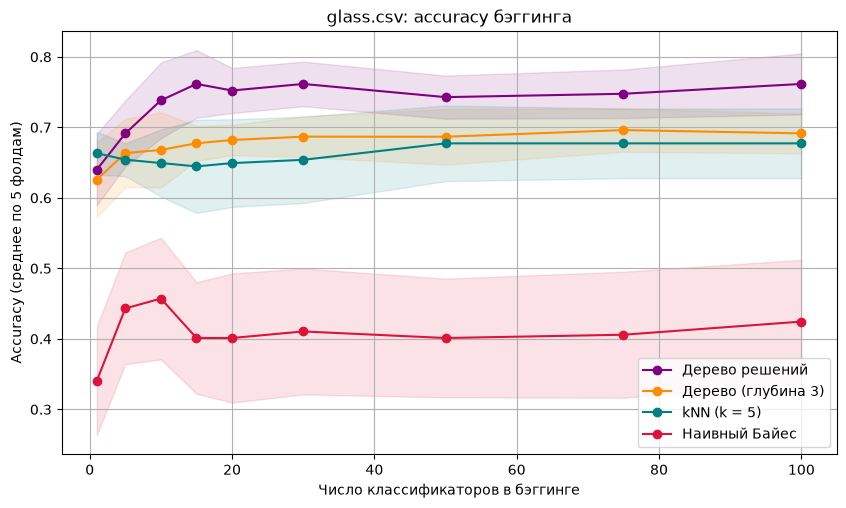

база,kNN (k = 5),Дерево (глубина 3),Дерево решений,Наивный Байес
n,,,,
0,0.645,0.663,0.678,0.438
1,0.663,0.626,0.640,0.341
5,0.654,0.663,0.691,0.443
10,0.649,0.668,0.738,0.457
15,0.645,0.677,0.762,0.401
20,0.649,0.682,0.752,0.401
30,0.654,0.687,0.762,0.411
50,0.677,0.687,0.743,0.401
75,0.677,0.696,0.748,0.406


In [26]:
# Бэггинг: 4 базовых классификатора, число моделей от 1 до 100, 5-блочная кросс-валидация
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
bases_bag = {'Дерево решений': DecisionTreeClassifier(random_state=2026),
             'Дерево (глубина 3)': DecisionTreeClassifier(max_depth=3, random_state=2026),
             'kNN (k = 5)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
             'Наивный Байес': make_pipeline(StandardScaler(), GaussianNB())}
n_list = [1, 5, 10, 15, 20, 30, 50, 75, 100]

def cv_scores(model, X, y):
    tr, te, f1 = [], [], []
    for i_tr, i_te in skf.split(X, y):
        model.fit(X.iloc[i_tr], y.iloc[i_tr])
        tr.append(accuracy_score(y.iloc[i_tr], model.predict(X.iloc[i_tr])))
        pred = model.predict(X.iloc[i_te])
        te.append(accuracy_score(y.iloc[i_te], pred))
        f1.append(f1_score(y.iloc[i_te], pred, average='macro'))
    return np.mean(tr), np.mean(te), np.std(te), np.mean(f1)

bag_rows = []
for name, base in bases_bag.items():
    tr, te, sd, f1 = cv_scores(base, X_g, y_g)
    bag_rows.append({'база': name, 'n': 0, 'train': tr, 'test': te, 'std': sd, 'macro-F1': f1})   # n = 0 - одна модель без бэггинга
    for n in n_list:
        bag = BaggingClassifier(estimator=base, n_estimators=n, random_state=2026)
        tr, te, sd, f1 = cv_scores(bag, X_g, y_g)
        bag_rows.append({'база': name, 'n': n, 'train': tr, 'test': te, 'std': sd, 'macro-F1': f1})
bag_tab = pd.DataFrame(bag_rows)

plt.figure(figsize=(10, 5.5))
for name, color in zip(bases_bag, ['purple', 'darkorange', 'teal', 'crimson']):
    part = bag_tab[(bag_tab['база'] == name) & (bag_tab['n'] > 0)]
    plt.plot(part['n'], part['test'], marker='o', color=color, label=name)
    plt.fill_between(part['n'], part['test'] - part['std'], part['test'] + part['std'], color=color, alpha=0.12)
plt.xlabel('Число классификаторов в бэггинге')
plt.ylabel('Accuracy (среднее по 5 фолдам)')
plt.title('glass.csv: accuracy бэггинга')
plt.legend()
plt.grid(True)
plt.show()

bag_tab.pivot(index='n', columns='база', values='test').round(3)

In [27]:
# Подробности: accuracy на обучении и macro-F1 (n = 0 - одна модель без бэггинга)
bag_tab.round(3)

,база,n,train,test,std,macro-F1
0,Дерево решений,0,1.000,0.678,0.062,0.641
1,Дерево решений,1,0.893,0.640,0.051,0.582
2,Дерево решений,5,0.963,0.691,0.047,0.610
3,Дерево решений,10,0.982,0.738,0.054,0.684
4,Дерево решений,15,0.995,0.762,0.048,0.697
5,Дерево решений,20,0.996,0.752,0.032,0.693
6,Дерево решений,30,1.000,0.762,0.032,0.693
7,Дерево решений,50,1.000,0.743,0.031,0.663
8,Дерево решений,75,1.000,0.748,0.034,0.691
9,Дерево решений,100,1.000,0.762,0.043,0.708


### Выводы по заданию 1
Бэггинг заметно повышает качество только у неустойчивой базовой модели. Для дерева решений без ограничения глубины accuracy растёт с 0.640 при одной модели до 0.762 при 15–30 моделях и затем перестаёт расти, что на 0.08 выше одиночного дерева. Для glass.csv лучший из рассмотренных вариантов - бэггинг глубоких деревьев с 30 моделями; дальнейшее увеличение ансамбля качества не добавляет, а только увеличивает время обучения.

Устойчивые модели (дерево глубины 3, kNN, наивный Байес) от увеличения ансамбля почти не выигрывают: бэггинг уменьшает разброс, но не исправляет большое смещение слишком простой или неподходящей к данным модели. Кроме того, один классификатор в бэггинге хуже модели, обученной на всей выборке, так как видит только бутстреп-подвыборку, поэтому ансамбль нужно сравнивать с обычной моделью без бэггинга.

## Задание 2. Бустинг AdaBoost: зависимость качества от числа классификаторов
Исследовать зависимость качества классификации на наборе vehicle.csv от числа классификаторов в ансамбле бустинга AdaBoost для разных базовых классификаторов, построить графики и определить, для каких базовых моделей увеличение ансамбля полезно.

In [28]:
vehicle = pd.read_csv('vehicle.csv')
X_v = vehicle.drop(columns='Class')
y_v = vehicle['Class']
print(X_v.shape)
print(y_v.value_counts().to_dict())
print('Константа (самый частый класс):', round(y_v.value_counts(normalize=True).max(), 3))

(846, 18)
{'bus': 218, 'saab': 217, 'opel': 212, 'van': 199}
Константа (самый частый класс): 0.258


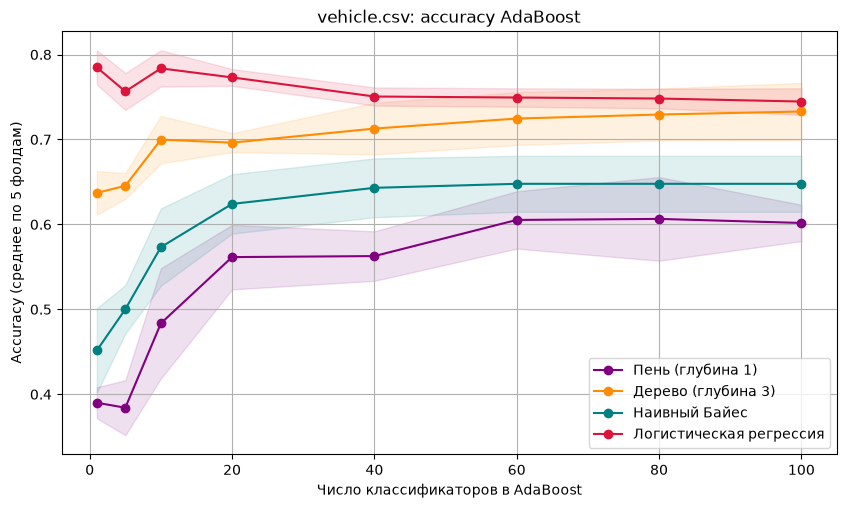

база,Дерево (глубина 3),Логистическая регрессия,Наивный Байес,Пень (глубина 1)
n,,,,
0,0.639,0.785,0.452,0.390
1,0.637,0.785,0.452,0.390
5,0.645,0.757,0.500,0.384
10,0.700,0.784,0.573,0.484
20,0.696,0.773,0.624,0.561
40,0.713,0.751,0.643,0.563
60,0.725,0.749,0.648,0.605
80,0.729,0.748,0.648,0.606
100,0.733,0.745,0.648,0.602


In [29]:
# AdaBoost: 4 базовых классификатора, число моделей от 1 до 100
# Признаки стандартизуются внутри каждого фолда (AdaBoost передаёт базовой модели веса объектов,
# поэтому базовая модель - сам классификатор, а не pipeline).
# Веса AdaBoost в сумме дают 1, поэтому у логистической регрессии C = число объектов фолда:
# тогда первый шаг бустинга совпадает с обычной логистической регрессией (C = 1).
def ada_bases(n_train):
    return {'Пень (глубина 1)': DecisionTreeClassifier(max_depth=1, random_state=2026),
            'Дерево (глубина 3)': DecisionTreeClassifier(max_depth=3, random_state=2026),
            'Наивный Байес': GaussianNB(),
            'Логистическая регрессия': LogisticRegression(C=n_train, max_iter=5000)}
n_list_ada = [1, 5, 10, 20, 40, 60, 80, 100]

folds = []
for i_tr, i_te in skf.split(X_v, y_v):
    sc = StandardScaler().fit(X_v.iloc[i_tr])
    folds.append((sc.transform(X_v.iloc[i_tr]), y_v.iloc[i_tr], sc.transform(X_v.iloc[i_te]), y_v.iloc[i_te]))

ada_rows = []
for name in ada_bases(1):
    for n in [0] + n_list_ada:              # n = 0 - одна модель без бустинга
        tr, te = [], []
        for Xtr, ytr, Xte, yte in folds:
            base = ada_bases(len(ytr))[name]
            if name == 'Логистическая регрессия' and n == 0:
                base = LogisticRegression(max_iter=5000)
            model = base if n == 0 else AdaBoostClassifier(estimator=base, n_estimators=n, learning_rate=1.0, random_state=2026)
            model.fit(Xtr, ytr)
            tr.append(accuracy_score(ytr, model.predict(Xtr)))
            te.append(accuracy_score(yte, model.predict(Xte)))
        ada_rows.append({'база': name, 'n': n, 'train': np.mean(tr), 'test': np.mean(te), 'std': np.std(te)})
ada_tab = pd.DataFrame(ada_rows)

plt.figure(figsize=(10, 5.5))
for name, color in zip(ada_bases(1), ['purple', 'darkorange', 'teal', 'crimson']):
    part = ada_tab[(ada_tab['база'] == name) & (ada_tab['n'] > 0)]
    plt.plot(part['n'], part['test'], marker='o', color=color, label=name)
    plt.fill_between(part['n'], part['test'] - part['std'], part['test'] + part['std'], color=color, alpha=0.12)
plt.xlabel('Число классификаторов в AdaBoost')
plt.ylabel('Accuracy (среднее по 5 фолдам)')
plt.title('vehicle.csv: accuracy AdaBoost')
plt.legend()
plt.grid(True)
plt.show()

ada_tab.pivot(index='n', columns='база', values='test').round(3)

In [30]:
# Accuracy на обучении и на контроле (n = 0 - одна модель без бустинга)
# и сколько моделей AdaBoost реально построил при n_estimators = 100 на каждом фолде
for name in ['Наивный Байес', 'Пень (глубина 1)']:
    built = [len(AdaBoostClassifier(estimator=ada_bases(len(ytr))[name], n_estimators=100, random_state=2026).fit(Xtr, ytr).estimators_)
             for Xtr, ytr, _, _ in folds]
    print(name, '- построено моделей по фолдам:', built)
ada_tab.round(3)

Наивный Байес - построено моделей по фолдам: [24, 32, 39, 44, 60]
Пень (глубина 1) - построено моделей по фолдам: [100, 100, 100, 100, 100]


,база,n,train,test,std
0,Пень (глубина 1),0,0.414,0.390,0.018
1,Пень (глубина 1),1,0.414,0.390,0.018
2,Пень (глубина 1),5,0.426,0.384,0.032
3,Пень (глубина 1),10,0.502,0.484,0.065
4,Пень (глубина 1),20,0.601,0.561,0.038
5,Пень (глубина 1),40,0.626,0.563,0.029
6,Пень (глубина 1),60,0.651,0.605,0.034
7,Пень (глубина 1),80,0.665,0.606,0.049
8,Пень (глубина 1),100,0.667,0.602,0.021
9,Дерево (глубина 3),0,0.686,0.639,0.026


### Выводы по заданию 2
AdaBoost полезен прежде всего для слабых базовых классификаторов. Решающий пень к 80 моделям прибавляет около 0.22 accuracy, наивный Байес к 60 моделям - около 0.20, после чего кривые выходят на плато; разрыв между обучением и контролем у них остаётся небольшим, так как бустинг уменьшает смещение модели. Для дерева глубины 3 прирост умеренный (около 0.10 к 100 моделям) и сопровождается заметным ростом разрыва между обучением и контролем.

Чем сильнее базовая модель, тем меньше пользы от увеличения ансамбля: у логистической регрессии бустинг даже ухудшает качество с 0.785 до 0.746. Поэтому число моделей нужно подбирать для каждой базы отдельно, а если базовая модель сама по себе сильная, бустинг применять не обязательно. Для vehicle.csv лучший результат среди рассмотренных вариантов даёт логистическая регрессия без бустинга.

## Задание 3. Стекинг: мета-классификатор для данных Titanic
Построить мета-классификатор методом стекинга для набора данных titanic_train.csv, оценить качество классификации, сравнить его с базовыми моделями ансамбля и применить обученный мета-классификатор к titanic_test.csv.

In [31]:
# Titanic: подготовка признаков (статистики для пропусков считаются только по обучающей части)
from sklearn.base import BaseEstimator, TransformerMixin

train = pd.read_csv('titanic_train.csv')
test = pd.read_csv('titanic_test.csv')
print('train:', train.shape, ' test:', test.shape, ' выживших:', train['Survived'].sum(), 'из', len(train))
print('Пропуски в train:', train.isna().sum()[train.isna().sum() > 0].to_dict())

class TitanicPrep(BaseEstimator, TransformerMixin):
    def _title(self, df):
        t = df['Name'].str.extract(r',\s*([^\.]+)\.')[0]
        t = t.replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
        return t.where(t.isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')
    def fit(self, df, y=None):
        title = self._title(df)
        self.age_by_title_ = df['Age'].groupby(title).median()
        self.age_ = df['Age'].median()
        self.fare_ = df['Fare'].median()
        self.emb_ = df['Embarked'].mode()[0]
        return self
    def transform(self, df):
        title = self._title(df)
        out = pd.DataFrame(index=df.index)
        out['Pclass'] = df['Pclass']
        out['Age'] = df['Age'].fillna(title.map(self.age_by_title_)).fillna(self.age_)
        out['Fare'] = df['Fare'].fillna(self.fare_)
        out['FamilySize'] = df['SibSp'] + df['Parch'] + 1
        out['IsAlone'] = (out['FamilySize'] == 1).astype(int)
        out['HasCabin'] = df['Cabin'].notna().astype(int)
        out['Sex_male'] = (df['Sex'] == 'male').astype(int)
        for t in ['Mr', 'Mrs', 'Miss', 'Master', 'Rare']:
            out['Title_' + t] = (title == t).astype(int)
        emb = df['Embarked'].fillna(self.emb_)
        for e in ['C', 'Q', 'S']:
            out['Emb_' + e] = (emb == e).astype(int)
        return out

X_t = train.drop(columns='Survived')
y_t = train['Survived']
TitanicPrep().fit(X_t).transform(X_t).head()

train: (891, 12)  test: (418, 11)  выживших: 342 из 891
Пропуски в train: {'Age': 177, 'Cabin': 687, 'Embarked': 2}


,Pclass,Age,Fare,FamilySize,IsAlone,HasCabin,Sex_male,Title_Mr,Title_Mrs,Title_Miss,Title_Master,Title_Rare,Emb_C,Emb_Q,Emb_S
0,3,22.0,7.2500,2,0,0,1,1,0,0,0,0,0,0,1
1,1,38.0,71.2833,2,0,1,0,0,1,0,0,0,1,0,0
2,3,26.0,7.9250,1,1,0,0,0,0,1,0,0,0,0,1
3,1,35.0,53.1000,2,0,1,0,0,1,0,0,0,0,0,1
4,3,35.0,8.0500,1,1,0,1,1,0,0,0,0,0,0,1


In [32]:
# Базовые модели и стекинг
from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_score, recall_score, roc_auc_score

def base_models():
    return [('Логистическая регрессия', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
            ('Дерево (глубина 4)', DecisionTreeClassifier(max_depth=4, random_state=2026)),
            ('kNN (k = 11)', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11))),
            ('Наивный Байес', GaussianNB())]

models_t = {'Константа («все погибли»)': DummyClassifier(strategy='most_frequent')}
for name, m in base_models():
    models_t[name] = m
models_t['Стекинг'] = StackingClassifier(estimators=[(f'm{i}', m) for i, (_, m) in enumerate(base_models())],
                                         final_estimator=LogisticRegression(max_iter=1000), cv=5)

# Отложенная выборка 20 % для подробной оценки + 5-блочная кросс-валидация по всему train
X_tr, X_ho, y_tr, y_ho = train_test_split(X_t, y_t, test_size=0.2, stratify=y_t, random_state=2026)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
res_rows, fitted = [], {}
for name, m in models_t.items():
    pipe = make_pipeline(TitanicPrep(), m).fit(X_tr, y_tr)
    fitted[name] = pipe
    pred = pipe.predict(X_ho)
    proba = pipe.predict_proba(X_ho)[:, 1]
    cv = cross_val_score(make_pipeline(TitanicPrep(), m), X_t, y_t, cv=cv5).mean()
    res_rows.append({'модель': name, 'accuracy': accuracy_score(y_ho, pred),
                     'precision': precision_score(y_ho, pred, zero_division=0), 'recall': recall_score(y_ho, pred),
                     'F1': f1_score(y_ho, pred), 'ROC-AUC': roc_auc_score(y_ho, proba), 'CV accuracy': cv})
res_t = pd.DataFrame(res_rows)
res_t.round(3)

,модель,accuracy,precision,recall,F1,ROC-AUC,CV accuracy
0,Константа («все погибли»),0.615,0.000,0.000,0.000,0.500,0.616
1,Логистическая регрессия,0.844,0.815,0.768,0.791,0.869,0.830
2,Дерево (глубина 4),0.838,0.823,0.739,0.779,0.854,0.806
3,kNN (k = 11),0.810,0.769,0.725,0.746,0.852,0.814
4,Наивный Байес,0.777,0.688,0.768,0.726,0.840,0.782
5,Стекинг,0.827,0.817,0.710,0.760,0.861,0.821


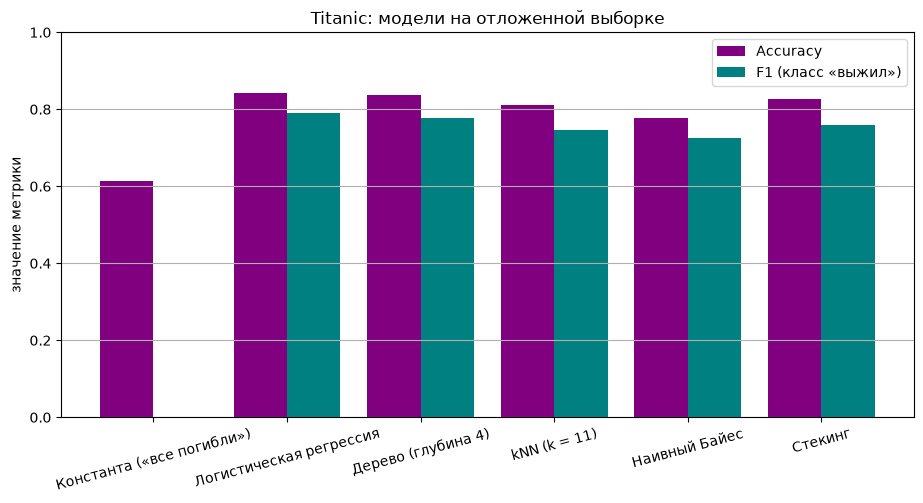

In [33]:
# Accuracy и F1 моделей на отложенной выборке
plt.figure(figsize=(11, 5))
x = np.arange(len(res_t))
plt.bar(x - 0.2, res_t['accuracy'], width=0.4, color='purple', label='Accuracy')
plt.bar(x + 0.2, res_t['F1'], width=0.4, color='teal', label='F1 (класс «выжил»)')
plt.xticks(x, res_t['модель'], rotation=15)
plt.ylim(0, 1)
plt.ylabel('значение метрики')
plt.title('Titanic: модели на отложенной выборке')
plt.legend()
plt.grid(True, axis='y')
plt.show()

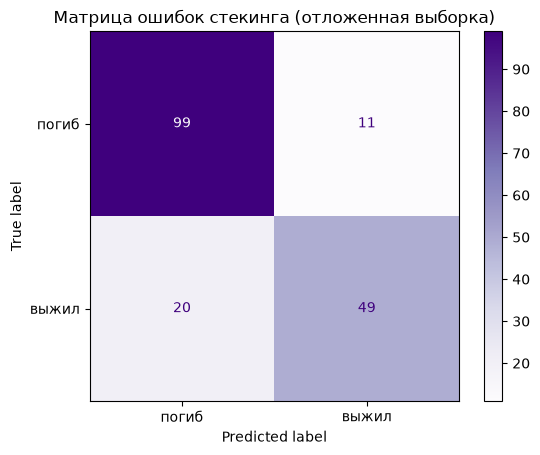

Коэффициенты мета-классификатора: {'Логистическая регрессия': np.float64(2.12), 'Дерево (глубина 4)': np.float64(2.23), 'kNN (k = 11)': np.float64(1.39), 'Наивный Байес': np.float64(-0.28)}


In [34]:
# Матрица ошибок стекинга и коэффициенты мета-классификатора
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(fitted['Стекинг'], X_ho, y_ho, display_labels=['погиб', 'выжил'], cmap='Purples')
plt.title('Матрица ошибок стекинга (отложенная выборка)')
plt.show()
meta = fitted['Стекинг'][-1].final_estimator_
print('Коэффициенты мета-классификатора:', dict(zip([n for n, _ in base_models()], meta.coef_[0].round(2))))

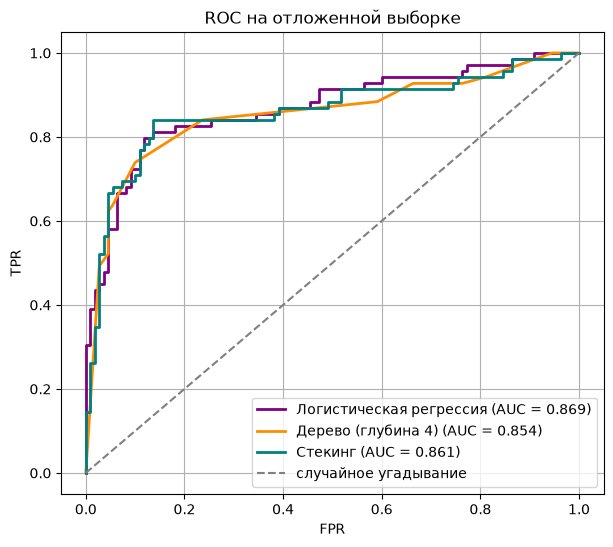

In [35]:
# ROC-кривые на отложенной выборке
from sklearn.metrics import roc_curve
plt.figure(figsize=(7, 6))
for name, color in [('Логистическая регрессия', 'purple'), ('Дерево (глубина 4)', 'darkorange'), ('Стекинг', 'teal')]:
    proba = fitted[name].predict_proba(X_ho)[:, 1]
    fpr, tpr, _ = roc_curve(y_ho, proba)
    plt.plot(fpr, tpr, linewidth=2, color=color, label=f'{name} (AUC = {roc_auc_score(y_ho, proba):.3f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='случайное угадывание')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC на отложенной выборке')
plt.legend()
plt.grid(True)
plt.show()

In [36]:
# Итоговый мета-классификатор на всём titanic_train.csv и прогноз для titanic_test.csv (меток в нём нет)
final = make_pipeline(TitanicPrep(), models_t['Стекинг']).fit(X_t, y_t)
pred_test = final.predict(test)
print('Предсказано выживших:', pred_test.sum(), ' погибших:', (pred_test == 0).sum(),
      ' доля выживших:', round(pred_test.mean(), 3))
pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': pred_test}).to_csv('titanic_predictions.csv', index=False)

Предсказано выживших: 168  погибших: 250  доля выживших: 0.402


### Выводы по заданию 3
Мета-классификатор, построенный методом стекинга из логистической регрессии, дерева решений, kNN и наивного Байеса, решает задачу намного лучше константного классификатора: accuracy на отложенной выборке 0.827 против 0.615, ROC-AUC 0.858. Однако лучшую из базовых моделей он не превзошёл: логистическая регрессия точнее и на отложенной выборке (0.844), и по кросс-валидации (0.830 против 0.821), хотя разница составляет всего несколько пассажиров.

Мета-классификатор присваивает наибольшие веса логистической регрессии и дереву решений, а наивному Байесу - небольшой отрицательный вес. Стекинг полезен, когда базовые модели ошибаются на разных объектах; на данных Titanic главная зависимость простая, и ошибки моделей во многом совпадают, поэтому объединение моделей почти ничего не добавляет. Файл titanic_test.csv меток не содержит, поэтому он использован только для применения готового мета-классификатора; доля предсказанных выживших согласуется с долей выживших в обучающей выборке.